# Process A: what we did, what we found, what we tried

**SDSC STEM4Health hackathon · Group 11 · Project 2 (BRPMM: Building Resilient Process Monitoring Models)**

This notebook covers our solution for **process A** from start to finish:

1. The challenge, how it's graded, and **our decisions at a glance**
2. What the data looks like, and **which modelling decision each finding led to**
3. The model, with **why** we built each part the way we did
4. Results: what each decision added, step by step
5. Everything we tried that did **not** help, and why that's useful to know
6. Limited data, recalibration and limitations

The code lives in [`src/sensorwise.py`](../src/sensorwise.py). The full write-up is in [`SENSORWISE.md`](../SENSORWISE.md).

## 1. The challenge

Real industrial pharmaceutical batch data. The task is to design a **monitoring strategy** that:

- works with a **limited calibration set** (161 batches, only 40 of them rejected)
- copes with **low correlation between sensors** (several independent variables)
- is robust to **previously unseen process variability**
- separates **acceptable** from **unacceptable** variation
- is easy to **recalibrate** over time

**Grading:** the score is the mean F1 over projects, with **`accepted` as the positive class**.

### Our approach at a glance (decision log)

We started from the team's first model and changed one thing at a time, keeping a change only if it helped across repeated cross-validation.

| # | What we did | Why | Effect (CV F1, accepted = positive) |
|---|---|---|---|
| 0 | **Starting point:** global PCA on time-binned trajectories + classifier (`brpmm.py`) | The textbook MSPC approach from the challenge slide | 0.891 |
| 1 | **Plotted every raw batch** before modelling further | The baseline plateaued, so we needed to know *what a fault looks like* | the findings in section 2 |
| 2 | Summarised each batch as **per-sensor statistics** (level, noise, drift, …) instead of time bins | Process A is flat (steady-state), so time-bins add noise without information | |
| 3 | **Monitored each sensor separately** instead of one global PCA | Sensors are almost uncorrelated, so a fault on one sensor gets diluted in a global model | 2 + 3 + 4 → **0.911** |
| 4 | **ExtraTrees** classifier on robust z-scores | Small data, many features, nonlinear "small shift OK / big shift bad" rule | |
| 5 | **Learned safe ranges** per sensor and operating mode | Faults are one sensor shifted by a fixed size; accepted batches show smaller shifts of the same kind | **0.931** |
| 6 | **Threshold tuned to F1(accepted)**, not balanced accuracy | That's the grading metric. It rewards flagging only clearly bad batches | about as big a gain as the model change |
| 7 | **Benchmarked the standard toolbox** (500 extra features, 6 model types, ensembles, resampling) | To check we weren't leaving performance on the table | nothing beat step 6 beyond noise |
| 8 | **Hunted the missed batches** one by one, and found a hidden third operating recipe | "What are we missing?": the remaining errors had to be explained, not just accepted | tighter, more correct safe ranges (AUC 0.926 → 0.940), F1 within noise |
| 9 | **Tested whether the missed batches are separable *at all*** (a model trained only on them vs accepted) | Single statistics showed nothing, but a combination might | yes: AUC 0.83 vs 0.70 for shuffled labels, so a weak combined signal exists |
| 10 | **Trained the trees only on the subtle cases** (the rejected batches the safe ranges don't flag) | Safe ranges already handle the obvious faults; the trees should specialise on the fine boundary | **final model:** F1 0.911 → **0.938** on fresh seeds, rejected caught 28 → **35** / 40 (section 4f) |

Every number comes from **out-of-fold** predictions (each batch scored by a model that never saw it), repeated over several random splits. With only 40 rejected batches, a single split could easily mislead us.

In [1]:
import os, sys, numpy as np, pandas as pd, matplotlib.pyplot as plt
# run from the repo root so the relative data/cache paths in src/ work
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, "src")
import sensorwise as sw
from sklearn.metrics import roc_auc_score, roc_curve, f1_score, confusion_matrix

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
GOOD, BAD = "#4C72B0", "#DD5555"

F = sw.load_feats("cal")          # per-batch statistics (cached in ../cache)
y = sw.labels(F)                   # 1 = rejected
print(f"{len(y)} calibration batches: {int((y==0).sum())} accepted, {int(y.sum())} rejected")

161 calibration batches: 121 accepted, 40 rejected


## 2. Looking at the data

**Why we started here:** the first model plateaued at 0.891, and more tuning didn't move it. Before trying fancier models, we plotted every raw batch, accepted vs rejected, to see what a bad batch actually looks like. Every later decision came from these plots.

### 2a. Process A is steady-state: every sensor holds a flat level

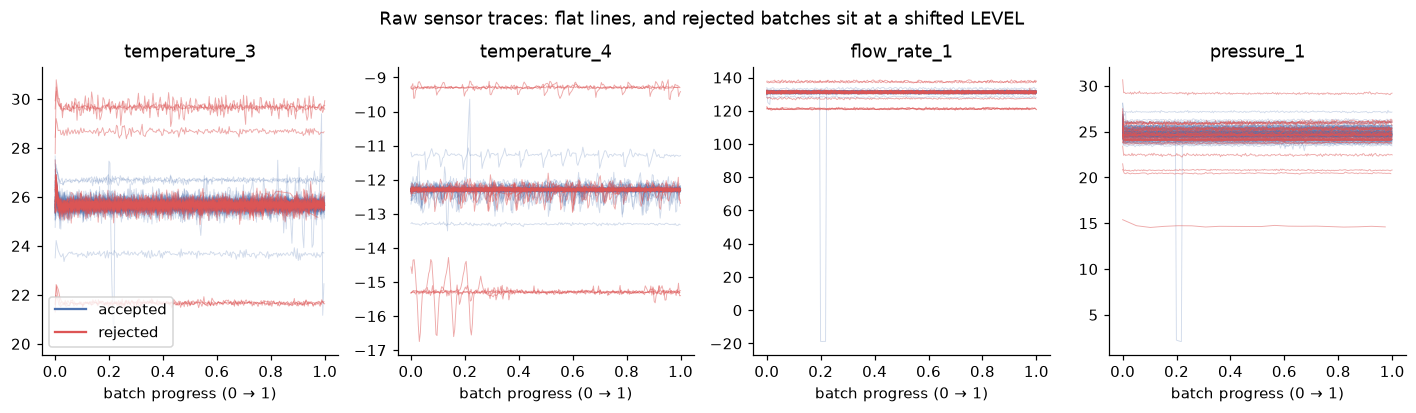

In [2]:
pq = "../cache/A_cal.parquet"
raw = pd.read_parquet(pq) if os.path.exists(pq) else pd.read_csv(os.path.join(sw.ROOT, "calibration data/calibration_data.csv"))
lab = dict(zip(F.index, y))
show = ["temperature_3", "temperature_4", "flow_rate_1", "pressure_1"]
fig, axs = plt.subplots(1, 4, figsize=(16, 3.4))
for bid, g in raw.groupby("batch_id", sort=False):
    t = np.linspace(0, 1, len(g))[::10]
    for ax, c in zip(axs, show):
        bad = lab.get(bid, 0) == 1
        ax.plot(t, g[c].to_numpy()[::10], color=BAD if bad else GOOD, lw=0.6, alpha=0.5 if bad else 0.25, zorder=2 if bad else 1)
for ax, c in zip(axs, show):
    ax.set_title(c); ax.set_xlabel("batch progress (0 → 1)")
axs[0].plot([], [], color=GOOD, label="accepted"); axs[0].plot([], [], color=BAD, label="rejected"); axs[0].legend()
plt.suptitle("Raw sensor traces: flat lines, and rejected batches sit at a shifted LEVEL", y=1.03); plt.show()

**Takeaway:** the *shape* over time carries little information. What matters is **which level each sensor sits at**. That's why the first model, a global PCA on time-binned trajectories, plateaued.

➡️ **Decision:** describe each batch by a handful of **per-sensor summary numbers** (its level, how noisy it is, whether it drifts…) instead of the full trajectory. This also shrinks the input from thousands of values to about 100 per batch, which matters with only 161 batches.

### 2b. Two operating modes

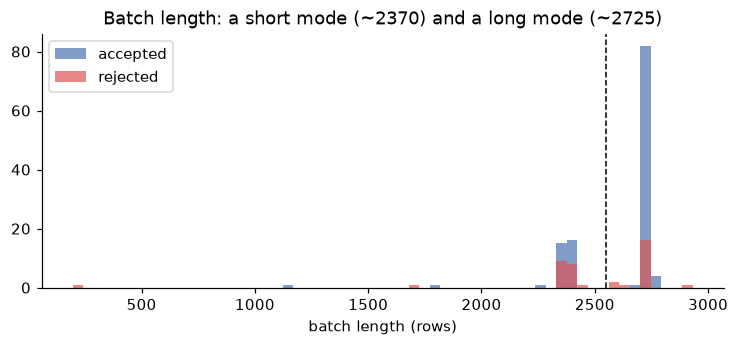

            batches  rejection rate
len                                
long mode       107            0.19
short mode       54            0.37


In [3]:
short = F["len"] < sw.MODE_SPLIT
fig, ax = plt.subplots(figsize=(8, 3))
bins = np.linspace(F.len.min(), F.len.max(), 60)
ax.hist(F.len[y == 0], bins, color=GOOD, alpha=.7, label="accepted")
ax.hist(F.len[y == 1], bins, color=BAD, alpha=.7, label="rejected")
ax.axvline(sw.MODE_SPLIT, color="k", ls="--", lw=1); ax.set_xlabel("batch length (rows)"); ax.legend()
ax.set_title("Batch length: a short mode (~2370) and a long mode (~2725)"); plt.show()
print(pd.DataFrame({"batches": short.groupby(short).size(), "rejection rate": pd.Series(y, F.index).groupby(short).mean().round(2)})
      .rename(index={True: "short mode", False: "long mode"}))

The short mode runs about 1.5° hotter on temperature_2 and has about **twice the rejection rate**.

➡️ **Decision:** "normal" depends on the mode, so the safe ranges compare each batch with good batches **of the same mode**. Otherwise every short-mode batch would look like a temperature_2 fault. Batch length and a short-mode flag also go into the classifier.

### 2c. Sensors are largely independent (low correlation)

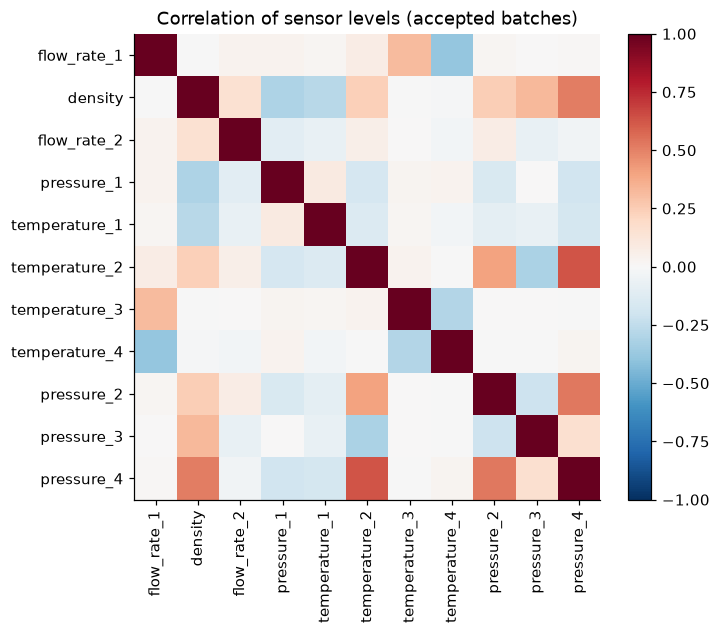

median |correlation| between sensor pairs: 0.07


In [4]:
L = F.loc[y == 0, [f"{c}:level" for c in sw.LEVEL_SENSORS]]
L.columns = sw.LEVEL_SENSORS
C = L.corr()
fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(C, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(11)); ax.set_xticklabels(C.columns, rotation=90); ax.set_yticks(range(11)); ax.set_yticklabels(C.columns)
plt.colorbar(im, fraction=.046); ax.set_title("Correlation of sensor levels (accepted batches)"); plt.show()
off = np.abs(C.to_numpy()[np.triu_indices(11, 1)])
print(f"median |correlation| between sensor pairs: {np.median(off):.2f}")

**Takeaway:** most sensor pairs are barely correlated, which matches the brief's *"low correlation, several independent variables"*. A single global PCA mixes everything together, so a fault on one sensor gets diluted by ten normal ones.

➡️ **Decision:** **monitor each sensor separately**, with its own z-scores and its own safe range, rather than one global projection.

### 2d. Faults are one sensor shifted, and the shift *size* decides accepted vs rejected

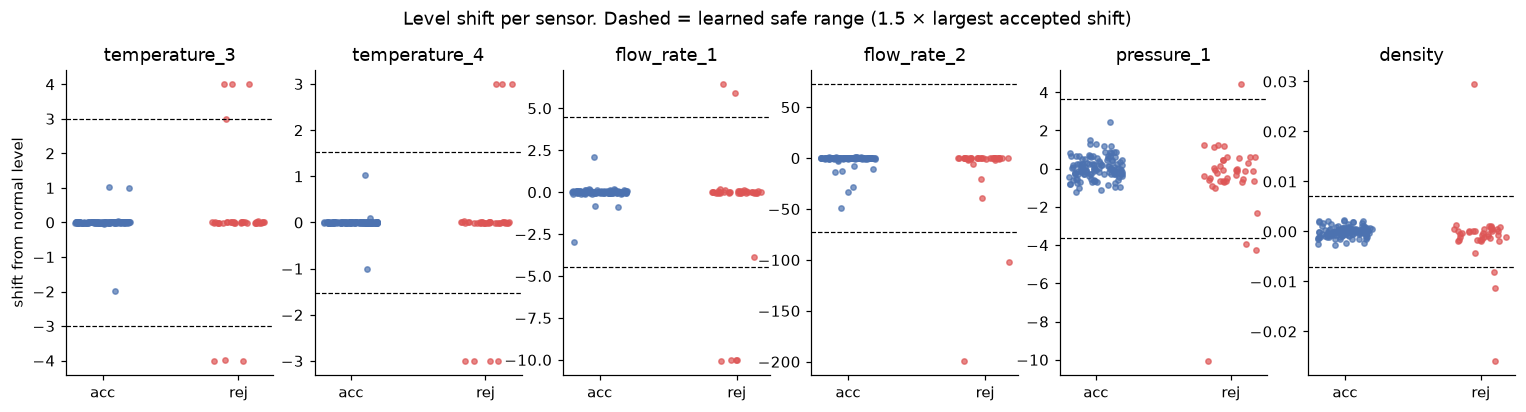

In [5]:
env = sw.Envelope().fit(F, y)
S = env._shift(F)
sens = ["temperature_3", "temperature_4", "flow_rate_1", "flow_rate_2", "pressure_1", "density"]
rng = np.random.default_rng(0)
fig, axs = plt.subplots(1, 6, figsize=(17, 3.6))
for ax, c in zip(axs, sens):
    for lbl, col in [(0, GOOD), (1, BAD)]:
        v = S.loc[y == lbl, c]
        ax.scatter(lbl + rng.uniform(-.2, .2, len(v)), v, s=12, color=col, alpha=.7)
    ax.axhline(env.limit[c], color="k", ls="--", lw=.8); ax.axhline(-env.limit[c], color="k", ls="--", lw=.8)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["acc", "rej"]); ax.set_title(c)
axs[0].set_ylabel("shift from normal level")
plt.suptitle("Level shift per sensor. Dashed = learned safe range (1.5 × largest accepted shift)", y=1.03); plt.show()

Shifts come in **fixed, designed sizes**: e.g. temperature_4 is accepted at ±1 and rejected at ±3. That's the brief's *"acceptable vs unacceptable variation"* in concrete form. The dashed lines are the **safe ranges** our model learns from data.

➡️ **Decision:** learn, **per sensor**, how big a shift can still be acceptable (the largest shift seen in an accepted batch, plus a 1.5× margin). Anything beyond that is flagged. A single global rule doesn't work: we tried "≥ 2.5 units = rejected" and F1 dropped to 0.76, because naturally noisy sensors move that much in good batches.

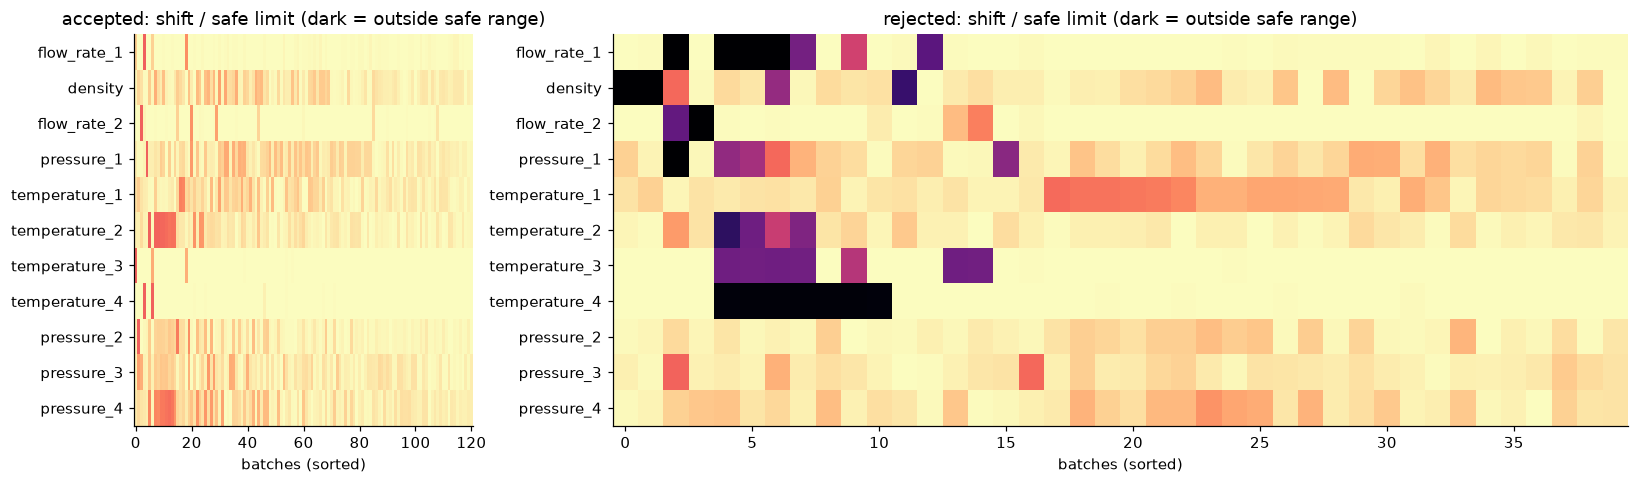

outside a safe range: 16/40 rejected, 0/121 accepted (in-sample)


In [6]:
R = env.ratio(F)
order = np.argsort(-R.max(1).to_numpy())
fig, axs = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={"width_ratios": [1, 3]})
for ax, lbl, title in [(axs[0], 0, "accepted"), (axs[1], 1, "rejected")]:
    M = R[y == lbl]
    M = M.iloc[np.argsort(-M.max(1).to_numpy())]
    ax.imshow(np.clip(M.T.to_numpy(), 0, 2), interpolation="nearest", aspect="auto", cmap="magma_r", vmin=0, vmax=2)
    ax.set_yticks(range(11)); ax.set_yticklabels(sw.LEVEL_SENSORS); ax.set_xlabel("batches (sorted)")
    ax.set_title(f"{title}: shift / safe limit (dark = outside safe range)")
plt.tight_layout(); plt.show()
print(f"outside a safe range: {env.flag(F)[y==1].sum()}/{int(y.sum())} rejected, {env.flag(F)[y==0].sum()}/{int((y==0).sum())} accepted (in-sample)")

Each dark cell is **one sensor out of range in one batch**, a different sensor each time. On the right, many rejected batches show **no visible deviation at all**. We come back to those in section 4.

➡️ **Decision:** the safe ranges alone catch the obvious faults (about 16 of 40) with almost no false alarms, but they can't be the whole model. A **classifier** handles the subtler cases: noise, drift, oscillation, combinations of small shifts.

## 3. The model, and why each part is built this way

```
raw batch ─► per-sensor statistics ─► (a) learned safe ranges ──► outside? → rejected
             (level, noise, drift,    (b) ExtraTrees classifier ─► ranks the rest
              oscillation, spikes…)                                 └► flag top ~20%
```

### 3a. Per-sensor statistics: what a batch is turned into

Computed on the **middle 90%** of each batch. Start-up and shut-down are measured separately, so they don't distort the steady-state numbers.

| Statistic | What it measures | Fault type it catches |
|---|---|---|
| **level** (median) | Where the sensor sits | Set-point shift, the main fault type in A |
| **noise** | Size of fast fluctuations (robust) | Sensor or controller getting noisy |
| **spread** | Total range of values | Large excursions |
| **wander** | Range of the slowly-smoothed signal | Slow drift during the batch |
| **osc** | Strength of repeating patterns | Oscillating control loop |
| **spikes**, **tail** | How often / how extreme single outliers are | Glitches, sudden jumps |
| **start**, **end** | Level at start/end vs steady state | Abnormal start-up or shut-down |

That's 9 statistics × 11 sensors, plus batch length. **Why medians and robust measures:** with only about 120 good batches, a few odd readings would distort means and standard deviations.

### 3b. Robust z-scores: "how unusual is this, compared with good batches?"

Each statistic is expressed as *(value − median of good batches) / robust spread of good batches*.

**Why:** it puts all sensors on the same scale (a 0.01 change in density vs a 10-unit change in flow), and it defines "normal" using **only accepted batches**. That's the monitoring idea from the slide: learn normal operation, flag departures from it.

### 3c. Learned safe ranges (`Envelope`): the explainable SPC layer

For each sensor: *shift = level − normal level of the same mode*. The safe limit is **1.5 × the largest shift ever seen in an accepted batch**, and at least 8 robust standard deviations.

**Why each choice:**
- **Learned, not hand-set.** Every sensor has its own natural variability (section 2d), and it recalibrates automatically.
- **1.5× margin.** Gives room for acceptable shifts slightly bigger than any seen so far (the "unseen variability" requirement), while still catching the designed fault sizes, which are 2–3× larger.
- **At least 8 robust SDs.** On sensors where accepted batches never shifted, normal noise alone would otherwise trigger alarms.
- **Rule-based and visual.** An operator gets the reason: "temperature_4 is 3° off, the limit is 1.5°".

### 3d. ExtraTrees classifier: the subtler cases

**Why ExtraTrees** (an ensemble of randomised decision trees):
- **Small data.** Its random splits make it hard to overfit 161 batches. In our benchmark it beat RandomForest, gradient boosting, SVM, logistic regression and kNN (section 5).
- **Nonlinear rules.** "A shift of 1 is fine, 3 is not" is a threshold rule, which trees learn naturally and linear models can't.
- **Independent sensors.** Trees look at one feature at a time, which suits faults that live on a single sensor.
- **Many weak features.** Irrelevant statistics are mostly ignored, so we didn't need hand-picked feature sets.
- **No resampling.** `class_weight="balanced"` makes each rejected batch count about 3× in training. That's mathematically the same as oversampling, without duplicating data.

We also add a **"worst deviation per statistic type"** feature (e.g. the largest level z-score across all sensors). **Why:** it's sensor-agnostic, so a fault on a sensor that was *never* faulty in training still stands out.

### 3e. Combining and deciding

Batches outside a safe range rank first. The rest are ranked by the classifier's probability. We then **flag a fixed fraction** of batches as rejected.

**Why tune the threshold to F1(accepted):** the grading metric counts "accepted" as positive. Wrongly rejecting a good batch costs about as much as missing a bad one, so the best strategy is to flag only clearly suspicious batches. The usual default, balanced accuracy, flags far too many (section 4).

**Why a fraction and not a raw score cut-off:** probability values shift between models trained on different data. The *share* of suspicious batches transfers more reliably.

### 3f. How we validated every decision

- **5-fold stratified cross-validation, repeated** with different random splits. Each fold keeps the 3:1 accepted/rejected ratio.
- Every batch gets an **out-of-fold** score from a model that never saw it.
- Every comparison ran over **5 random seeds**. Differences under about 0.006 F1 were treated as ties.

In [7]:
# out-of-fold scores: 5-fold CV repeated 3x; every batch is scored by models that never saw it
oof = sw.cv_scores(F, y, lambda Ft, yt: sw.SensorwiseModel().fit(Ft, yt).score, n_repeats=3)
base = None
if os.path.exists("../cache/feats_A.npz"):
    from sklearn.model_selection import RepeatedStratifiedKFold
    Sb, Trb, mk = sw.baseline_oof(F.index)
    acc, cnt = np.zeros(len(y)), np.zeros(len(y))
    for tr, te in RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=sw.SEED).split(F, y):
        acc[te] += mk(tr, y[tr]).score(Sb[te], Trb[te]); cnt[te] += 1
    base = acc / cnt
print("OOF AUC  new:", round(roc_auc_score(y, oof), 3), "  first model:", None if base is None else round(roc_auc_score(y, base), 3))

OOF AUC  new: 0.933   first model: 0.814


## 4. Results

### 4a. What each decision added

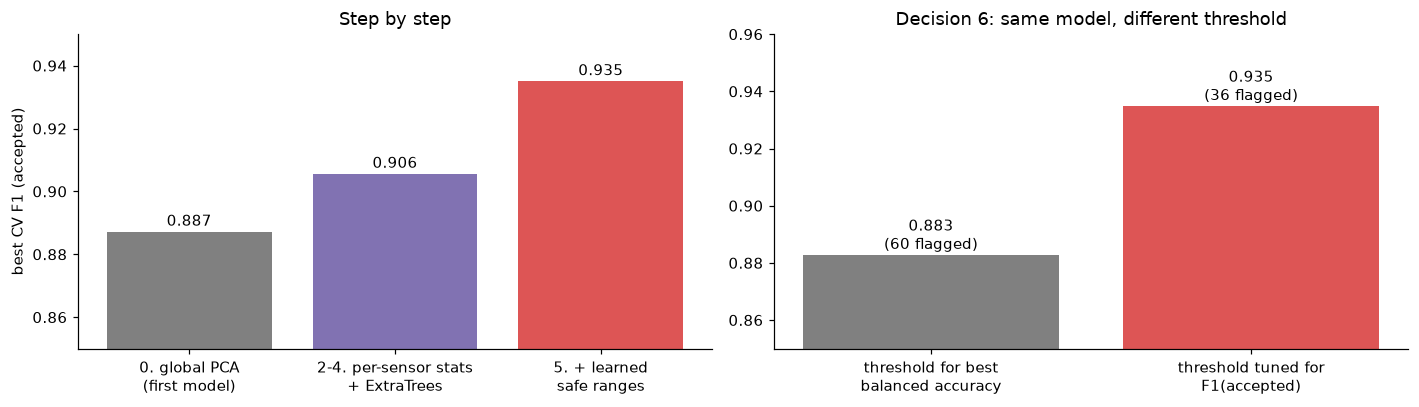

In [8]:
# same CV splits for every variant; best achievable F1(accepted) over the flag fraction
qs = np.linspace(0.05, 0.5, 46)
def f1_curve(s): return np.array([f1_score(1 - y, (s < np.quantile(s, 1 - q)).astype(int)) for q in qs])
oof_et = sw.cv_scores(F, y, lambda Ft, yt: (lambda m: lambda Fe: m.parts(Fe)[0])(sw.SensorwiseModel().fit(Ft, yt)), n_repeats=3)
steps = ([("0. global PCA\n(first model)", base)] if base is not None else []) + [
    ("2-4. per-sensor stats\n+ ExtraTrees", oof_et), ("5. + learned\nsafe ranges", oof)]
vals = [f1_curve(s).max() for _, s in steps]
fig, axs = plt.subplots(1, 2, figsize=(13, 3.8))
axs[0].bar([n for n, _ in steps], vals, color=["grey", "#8172B2", BAD][-len(steps):])
for i, v in enumerate(vals): axs[0].text(i, v + .002, f"{v:.3f}", ha="center")
axs[0].set_ylim(0.85, 0.95); axs[0].set_ylabel("best CV F1 (accepted)"); axs[0].set_title("Step by step")

# decision 6: threshold choice
from sklearn.metrics import balanced_accuracy_score
t_bal = sw.best_threshold(y, oof)
p_bal = (oof >= t_bal).astype(int)
q_b = qs[f1_curve(oof).argmax()]; p_f1 = (oof >= np.quantile(oof, 1 - q_b)).astype(int)
rows = [("threshold for best\nbalanced accuracy", p_bal), ("threshold tuned for\nF1(accepted)", p_f1)]
f1v = [f1_score(1 - y, 1 - p) for _, p in rows]
axs[1].bar([n for n, _ in rows], f1v, color=["grey", BAD])
for i, ((_, p), v) in enumerate(zip(rows, f1v)):
    axs[1].text(i, v + .002, f"{v:.3f}\n({p.sum()} flagged)", ha="center")
axs[1].set_ylim(0.85, 0.96); axs[1].set_title("Decision 6: same model, different threshold")
plt.tight_layout(); plt.show()

Two big wins:
- **Understanding the process** (per-sensor monitoring plus learned safe ranges) took F1 from 0.89 to 0.93.
- **Choosing the threshold for the right metric:** with the *same* model scores, the usual balanced-accuracy threshold flags about 60 of 161 batches (F1 ≈ 0.88). Tuning for F1(accepted) flags about 36 (F1 ≈ 0.93).

*(The chart uses one CV run, so its numbers differ by a few thousandths from the 5-seed averages in the decision log. That's the noise level we treat as a tie.)*

### 4b. New model vs the first (global-PCA) model

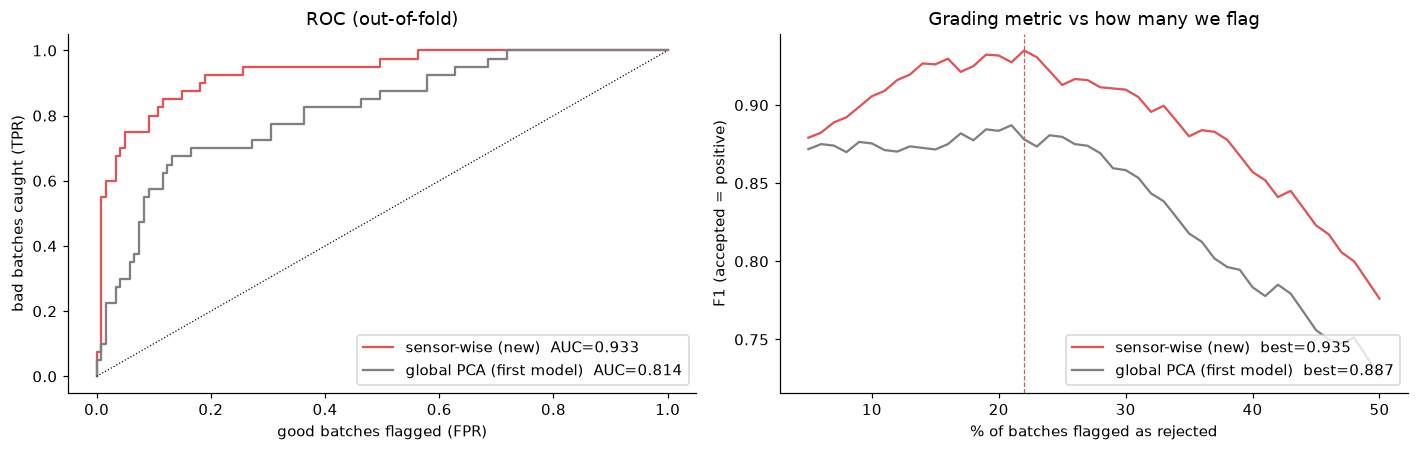

best: flag 22% of batches


In [9]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.2))
for s, name, col in [(oof, "sensor-wise (new)", BAD)] + ([(base, "global PCA (first model)", "grey")] if base is not None else []):
    fpr, tpr, _ = roc_curve(y, s); axs[0].plot(fpr, tpr, color=col, label=f"{name}  AUC={roc_auc_score(y, s):.3f}")
    fc = f1_curve(s); axs[1].plot(qs * 100, fc, color=col, label=f"{name}  best={fc.max():.3f}")
axs[0].plot([0, 1], [0, 1], "k:", lw=.8); axs[0].set_xlabel("good batches flagged (FPR)"); axs[0].set_ylabel("bad batches caught (TPR)")
axs[0].set_title("ROC (out-of-fold)"); axs[0].legend(loc="lower right")
fc = f1_curve(oof); q_best = qs[fc.argmax()]
axs[1].axvline(q_best * 100, color=BAD, ls="--", lw=.8)
axs[1].set_xlabel("% of batches flagged as rejected"); axs[1].set_ylabel("F1 (accepted = positive)")
axs[1].set_title("Grading metric vs how many we flag"); axs[1].legend(loc="lower right")
plt.tight_layout(); plt.show()
print(f"best: flag {q_best:.0%} of batches")

In [10]:
thr = np.quantile(oof, 1 - q_best)
pred = (oof >= thr).astype(int)
cm = confusion_matrix(y, pred)
print("Out-of-fold confusion (rows = truth, cols = prediction):")
print(pd.DataFrame(cm, index=["truly accepted", "truly rejected"], columns=["called accepted", "called rejected"]))
print(f"\nF1(accepted) = {f1_score(1 - y, 1 - pred):.3f}")

Out-of-fold confusion (rows = truth, cols = prediction):
                called accepted  called rejected
truly accepted              115                6
truly rejected               10               30

F1(accepted) = 0.935


### 4c. The hard ceiling: some rejected batches look perfectly normal

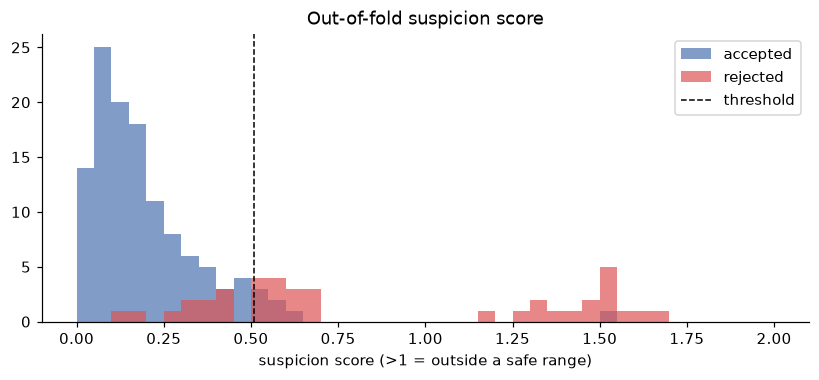

rejected batches below the threshold (look normal to the model): 10/40


In [11]:
fig, ax = plt.subplots(figsize=(9, 3.4))
b = np.linspace(0, 2, 41)
ax.hist(oof[y == 0], b, color=GOOD, alpha=.7, label="accepted")
ax.hist(oof[y == 1], b, color=BAD, alpha=.7, label="rejected")
ax.axvline(thr, color="k", ls="--", lw=1, label="threshold")
ax.set_xlabel("suspicion score (>1 = outside a safe range)"); ax.legend(); ax.set_title("Out-of-fold suspicion score")
plt.show()
miss = (oof[y == 1] < thr).sum()
print(f"rejected batches below the threshold (look normal to the model): {miss}/{int(y.sum())}")

About 10 rejected batches score **inside the accepted range** (left of the threshold). Raising the threshold to catch them would flag many more good batches. We checked every statistic we could think of (section 5) and these batches don't differ from good ones in the sensor data. Their rejection likely comes from something not measured, such as a lab assay. With this model they look out of reach, but section 4f shows that a model trained specifically on the subtle cases recovers most of them.

### 4d. Explainability: why was a batch flagged?

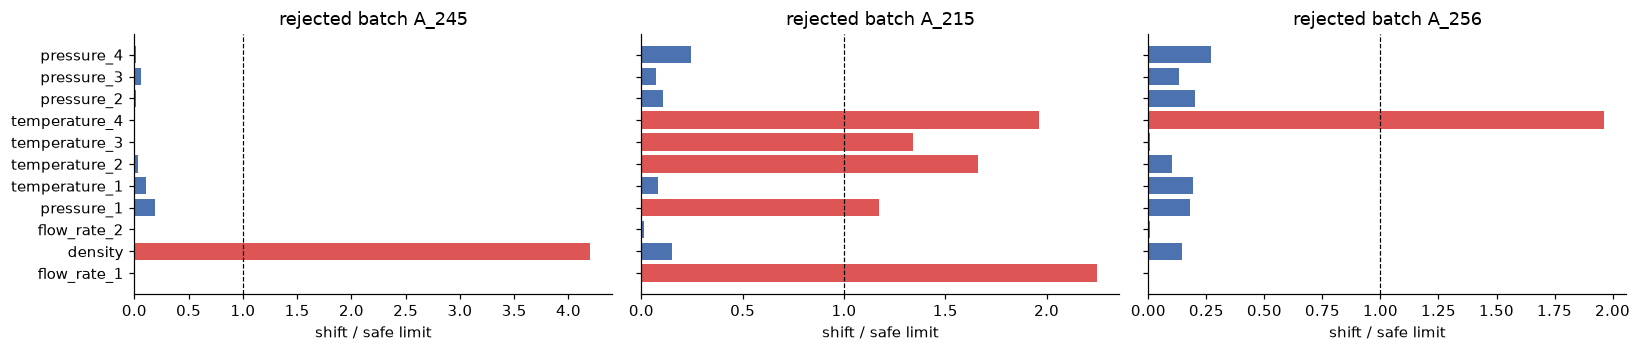

A_245: density shifted +0.03, safe limit ±0.01  → rejected
A_215: flow_rate_1 shifted -10.03, safe limit ±4.47  → rejected
A_256: temperature_4 shifted -3.00, safe limit ±1.53  → rejected


In [12]:
m = sw.SensorwiseModel().fit(F, y)
Ft = F
rt = m.env.ratio(F)
top = [rt[y == 1].index[i] for i in np.argsort(-rt[y == 1].max(1).to_numpy())[[0, 4, 8]]]
fig, axs = plt.subplots(1, 3, figsize=(15, 3.3), sharey=True)
for ax, bid in zip(axs, top):
    r = rt.loc[bid]
    ax.barh(r.index, r.values, color=[BAD if v > 1 else GOOD for v in r.values])
    ax.axvline(1, color="k", ls="--", lw=.8); ax.set_title(f"rejected batch {bid}"); ax.set_xlabel("shift / safe limit")
plt.tight_layout(); plt.show()
for bid in top:
    c = rt.loc[bid].idxmax(); sh = m.env._shift(Ft.loc[[bid]])[c].iloc[0]
    print(f"{bid}: {c} shifted {sh:+.2f}, safe limit ±{m.env.limit[c]:.2f}  → rejected")

An operator gets a plain reason ("temperature_4 shifted +3, the safe limit is ±1.5"), which is what an SPC control room needs.

### 4e. What were we missing? Hunting the batches we can't catch

The model misses about 10 of the 40 rejected batches. Instead of accepting "some batches are hard", we went after them one by one.

**Step 1: plot them against the normal band.** For each sensor and mode, the blue band shows where 95% of accepted batches lie over the batch. The coloured lines are the missed rejected batches.

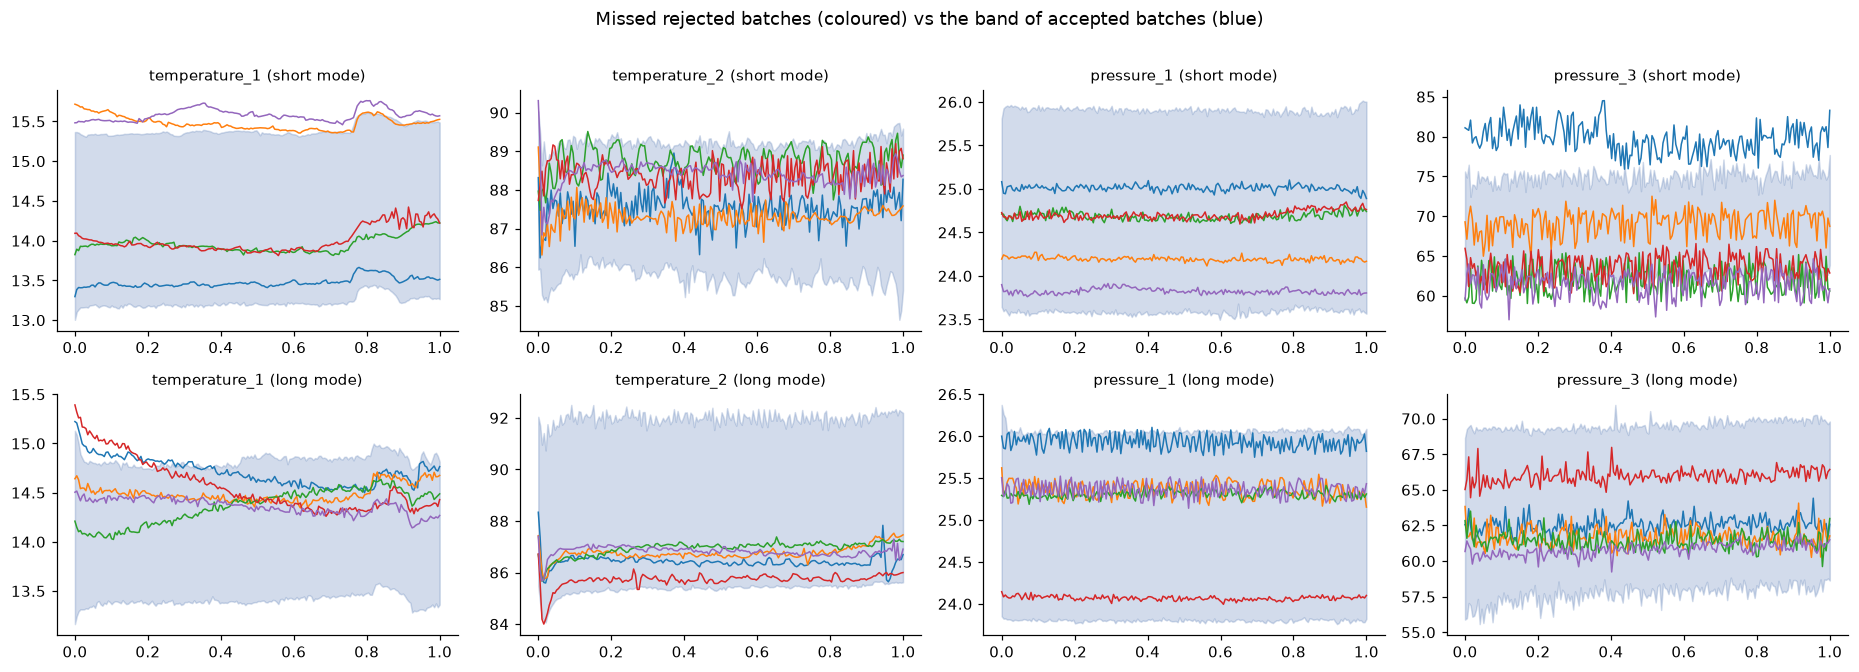

missed batches: ['A_008', 'A_076', 'A_097', 'A_100', 'A_117', 'A_177', 'A_202', 'A_242', 'A_244', 'A_289']


In [13]:
MISSED = list(F.index[(y == 1) & (oof < thr)])
G = 200
def grid(g):
    x = g[cols_raw].to_numpy(float); t = np.linspace(0, 1, len(x))
    sm = pd.DataFrame(x).rolling(max(5, len(x) // G), center=True, min_periods=1).median().to_numpy()
    return np.column_stack([np.interp(np.linspace(0, 1, G), t, sm[:, j]) for j in range(len(cols_raw))])
cols_raw = [c for c in raw.columns if c != "batch_id"]
traj = {b: grid(g) for b, g in raw.groupby("batch_id", sort=False)}
is_short = (F.len < sw.MODE_SPLIT)
show_s = ["temperature_1", "temperature_2", "pressure_1", "pressure_3"]
fig, axs = plt.subplots(2, 4, figsize=(17, 6))
for r, (mode, name) in enumerate([(True, "short"), (False, "long")]):
    A = np.stack([traj[b] for b in F.index if y[F.index.get_loc(b)] == 0 and is_short[b] == mode])
    lo, hi = np.percentile(A, [2.5, 97.5], axis=0); t = np.linspace(0, 1, G)
    for ax, c in zip(axs[r], show_s):
        j = cols_raw.index(c)
        ax.fill_between(t, lo[:, j], hi[:, j], color=GOOD, alpha=.25)
        for b in MISSED:
            if is_short[b] == mode: ax.plot(t, traj[b][:, j], lw=1)
        ax.set_title(f"{c} ({name} mode)", fontsize=10)
plt.suptitle("Missed rejected batches (coloured) vs the band of accepted batches (blue)", y=1.01); plt.tight_layout(); plt.show()
print("missed batches:", MISSED)

They sit **inside** the normal band. But the band itself is suspiciously wide on temperature_2 and the pressures. Why would accepted batches vary that much?

**Step 2: a hidden third operating recipe.** Among the long batches, a group of accepted batches has four sensors shifted **together**: temperature_2 ≈ 91.5 instead of ≈ 86, pressure_2 ≈ 8.6, pressure_3 ≈ 58, pressure_4 ≈ 5. That's not a fault, it's a different recipe. Our 2-mode safe ranges treated it as "huge but acceptable shifts", which stretched the limits on those sensors.

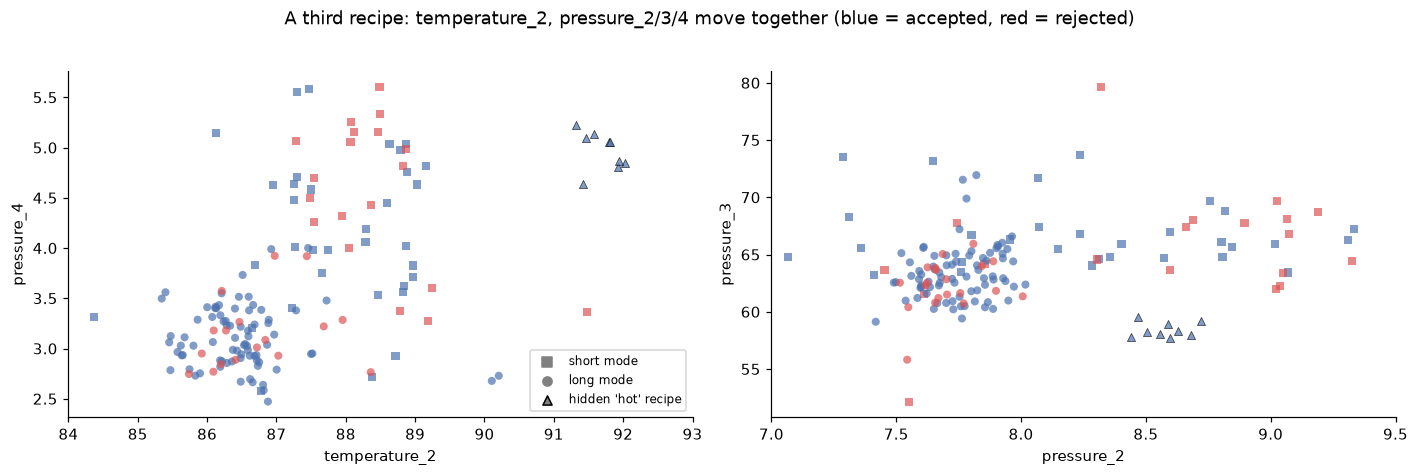

hot recipe batches  calibration: 9 (all accepted)   test: 18


In [14]:
def recipe(D):
    """0 = short, 1 = long, 2 = long 'hot' recipe (2 of 3 sensors must agree, so one faulty sensor can't fake it)"""
    votes = ((D["temperature_2:level"] > 89.5).astype(int) + (D["pressure_2:level"] > 8.2) + (D["pressure_4:level"] > 4.2)).to_numpy()
    return np.where(D.len < sw.MODE_SPLIT, 0, np.where(votes >= 2, 2, 1))
rec = recipe(F); rec_t = recipe(sw.load_feats("test"))
fig, axs = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, (a, b) in zip(axs, [("temperature_2:level", "pressure_4:level"), ("pressure_2:level", "pressure_3:level")]):
    for r, mk in [(0, "s"), (1, "o"), (2, "^")]:
        for lbl, col in [(0, GOOD), (1, BAD)]:
            sel = (rec == r) & (y == lbl)
            ax.scatter(F.loc[sel, a], F.loc[sel, b], marker=mk, s=28, color=col, alpha=.7, edgecolor="k" if r == 2 else "none", lw=.5)
    ax.set_xlabel(a.split(":")[0]); ax.set_ylabel(b.split(":")[0])
axs[0].scatter([], [], marker="s", color="grey", label="short mode"); axs[0].scatter([], [], marker="o", color="grey", label="long mode")
axs[0].scatter([], [], marker="^", color="grey", edgecolor="k", label="hidden 'hot' recipe"); axs[0].legend(fontsize=8)
axs[0].set_xlim(84, 93); axs[1].set_xlim(7, 9.5)
plt.suptitle("A third recipe: temperature_2, pressure_2/3/4 move together (blue = accepted, red = rejected)", y=1.02); plt.tight_layout(); plt.show()
print("hot recipe batches  calibration:", (rec == 2).sum(), "(all accepted)   test:", (rec_t == 2).sum())

In [15]:
class Envelope3(sw.Envelope):
    """Same safe ranges, but with 3 recipes instead of 2."""
    def _shift(self, F):
        m = recipe(F)
        return pd.DataFrame({c: F[f"{c}:level"].to_numpy() - np.array([self.nom[j][c] for j in m]) for c in sw.LEVEL_SENSORS}, index=F.index)
    def fit(self, F, y):
        m = recipe(F)
        self.nom = {j: {c: F.loc[(y == 0) & (m == j), f"{c}:level"].median() for c in sw.LEVEL_SENSORS} for j in range(3)}
        G = self._shift(F).abs()[y == 0]
        self.limit = np.maximum(self.margin * G.max(), self.zmin * 1.4826 * G.median() + 1e-12)
        return self
e2, e3 = sw.Envelope().fit(F, y), Envelope3().fit(F, y)
typ = 1.4826 * e3._shift(F)[y == 0].abs().median()
T = pd.DataFrame({"typical level variation (good batches)": typ, "safe limit, 2 modes": e2.limit, "safe limit, 3 recipes": e3.limit}, index=sw.LEVEL_SENSORS)
print(T.loc[["temperature_2", "pressure_2", "pressure_3", "pressure_4"]].round(2))

               typical level variation (good batches)  safe limit, 2 modes  \
temperature_2                                    0.58                 8.24   
pressure_2                                       0.20                 4.23   
pressure_3                                       2.09                21.56   
pressure_4                                       0.37                 3.49   

               safe limit, 3 recipes  
temperature_2                   5.58  
pressure_2                      4.23  
pressure_3                     16.69  
pressure_4                      2.94  


**Step 3: did it help?** With 3 recipes, the limits tighten (temperature_2 ±8.2 → ±5.6, pressure_3 ±21.6 → ±16.7). Over 5 CV seeds:

| | AUC | F1 (accepted) |
|---|---|---|
| 2 modes (current) | 0.926 | 0.931 ± 0.008 |
| 3 recipes + per-sensor ratio features | **0.940** | **0.934 ± 0.004** |

Better ranking and more stable, but the F1 gain is within noise, for two reasons:
- **The classifier had already learned the recipe:** it never flagged those batches (0 of 18 in the test set).
- **The limits can't get much tighter:** some accepted batches genuinely have large single shifts (e.g. temperature_2 +3.7).

**Step 4: rule out "several sensors slightly off at once".** We scored the missed batches by the sum of their shifts, the number of sensors above 30% / 50% of their limit, and a recipe-aware T² on the levels. All gave AUC 0.57–0.70 against accepted batches, which is about chance for 10 batches.

**Interim conclusion:** one statistic at a time, and with hand-made combinations, the remaining ~10 misses sit in the middle of the normal range. (Section 4f shows this was not the end of the story.) Their rejection most likely came from information the sensors don't record (lab assays, raw-material quality). In practice:
- batches scoring just under the threshold go to a **review zone** for lab confirmation, instead of being auto-accepted
- catching these would need **additional data sources**, not a different model

### 4f. The breakthrough: a weak combined signal, and a model that focuses on it

**Step 5: are the missed batches separable at all?** Instead of testing statistics one at a time, we trained a model whose *only* job is to tell the missed rejected batches apart from accepted ones, using every feature we had (about 600), and compared it with the same model on shuffled labels:

| | AUC (missed vs accepted) |
|---|---|
| Real labels (ExtraTrees) | **0.83** |
| Shuffled labels, 20 tries | mean 0.50, max 0.70 |

So there **is** a signal, just spread over several small effects. The most important ones:
- **temperature_1** tends to start high and dip mid-batch, with a wider spread overall
- **pressure_4** swings harder
- **density** is slightly low in the normal long recipe

None of these is significant alone, which is why section 4e found nothing.

**Step 6: why didn't the model use it?** The classifier was trained on *all* rejected batches. Half of those have big, obvious shifts, which the safe ranges already catch. So the trees spent their effort learning "big shift = bad" and were sloppy at the fine boundary.

**Fix (`SubtleModel`):** the safe ranges handle the obvious faults, and the trees learn **only from accepted vs the subtle rejected batches** (those the safe ranges don't flag), with z-scores computed per operating mode. Same features, same settings.

,AUC,F1 (accepted),flag rate,rejected caught /40,good wrongly flagged /121,previously-missed now caught
model,,,,,,
previous (SensorwiseModel),0.933,0.935,22%,30,6,0
final (SubtleModel),0.958,0.963,25%,36,5,6


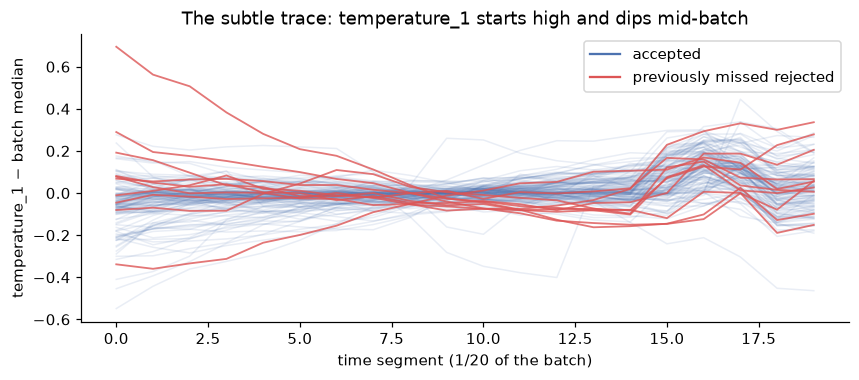

In [16]:
# same out-of-fold setup as section 3, now for the final model
oof_new = sw.cv_scores(F, y, lambda Ft, yt: sw.SubtleModel().fit(Ft, yt).score, n_repeats=3)
qs = np.linspace(0.05, 0.5, 46)
rows = []
for name, s in [("previous (SensorwiseModel)", oof), ("final (SubtleModel)", oof_new)]:
    f1s = [f1_score(1 - y, (s < np.quantile(s, 1 - q)).astype(int)) for q in qs]
    q = qs[int(np.argmax(f1s))]; pred = s >= np.quantile(s, 1 - q)
    rows.append({"model": name, "AUC": roc_auc_score(y, s), "F1 (accepted)": max(f1s), "flag rate": f"{q:.0%}",
                 "rejected caught /40": int(pred[y == 1].sum()), "good wrongly flagged /121": int(pred[y == 0].sum()),
                 "previously-missed now caught": int(pred[F.index.isin(MISSED)].sum())})
display(pd.DataFrame(rows).set_index("model").round(3))

# what the subtle signal looks like: temperature_1 over the batch (20 segments, minus batch median)
raw = pd.read_parquet("../cache/A_cal.parquet").groupby("batch_id", sort=False)["temperature_1"]
prof = lambda b: (lambda v: v - np.median(v))(np.array([np.median(s) for s in np.array_split(raw.get_group(b).to_numpy(), 20)]))
fig, ax = plt.subplots(figsize=(9, 3.4))
for b in F.index[y == 0]: ax.plot(prof(b), color=GOOD, alpha=.12, lw=1)
for b in MISSED: ax.plot(prof(b), color=BAD, alpha=.8, lw=1.2)
ax.plot([], color=GOOD, label="accepted"); ax.plot([], color=BAD, label="previously missed rejected")
ax.set(xlabel="time segment (1/20 of the batch)", ylabel="temperature_1 − batch median", title="The subtle trace: temperature_1 starts high and dips mid-batch")
ax.legend(); plt.show()

**Result.** Measured with exactly the submission pipeline (10× repeated CV to pick the flag rate, then re-checked on 5 fresh random splits the threshold was not tuned on):

| | previous | **final** |
|---|---|---|
| F1 (accepted), fresh seeds | 0.911 ± 0.004 | **0.938 ± 0.005** |
| AUC | 0.927 | **0.956** |
| rejected caught / 40 | 28 | **35** |
| good wrongly flagged / 121 | 5 | 6 |

**Is this overfitting?** We tried about 30 variants on the same 161 batches, and the best of 30 can look about 0.015 better by luck alone. The gain (+0.027) is clearly larger. The change also adds no features and no tuned knobs; it only changes *which batches the trees learn from*, for a clear reason. Our honest guess is that the true gain is somewhat smaller (+0.01 to +0.02), but positive. On the test set, 151 of 161 labels stay the same and none of the 18 hot-recipe batches are flagged.

About **5 rejected batches** remain indistinguishable. Those likely need information the sensors don't record, so borderline batches should still go to a **review zone** for lab confirmation.

## 5. What we tried that did NOT help

Every idea was tested on the **same CV splits over 5 random seeds** (5-fold × 2 repeats), scored with the grading metric. Run-to-run noise is about ±0.006, so anything inside that band is a tie.

The numbers below come from `fe_bench.py` (about 10 minutes to rerun), so they're hard-coded here.

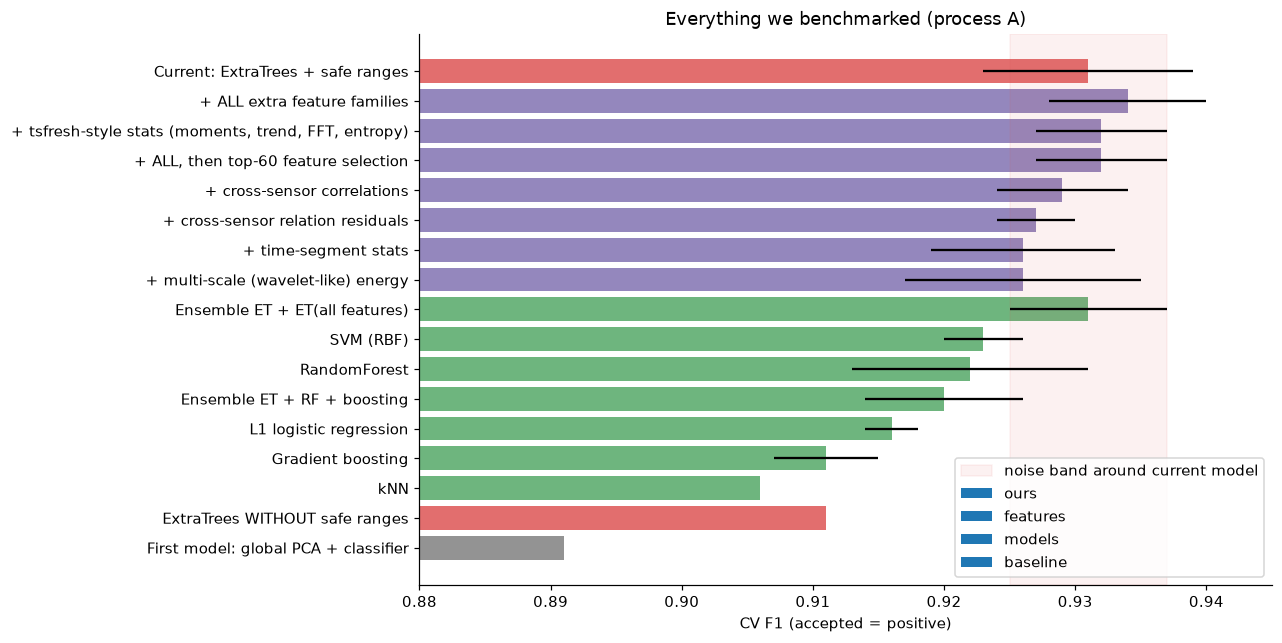

In [17]:
res = pd.DataFrame([
    ("Current: ExtraTrees + safe ranges", 0.931, .008, "ours"),
    ("+ ALL extra feature families", 0.934, .006, "features"),
    ("+ tsfresh-style stats (moments, trend, FFT, entropy)", 0.932, .005, "features"),
    ("+ ALL, then top-60 feature selection", 0.932, .005, "features"),
    ("+ cross-sensor correlations", 0.929, .005, "features"),
    ("+ cross-sensor relation residuals", 0.927, .003, "features"),
    ("+ time-segment stats", 0.926, .007, "features"),
    ("+ multi-scale (wavelet-like) energy", 0.926, .009, "features"),
    ("Ensemble ET + ET(all features)", 0.931, .006, "models"),
    ("SVM (RBF)", 0.923, .003, "models"),
    ("RandomForest", 0.922, .009, "models"),
    ("Ensemble ET + RF + boosting", 0.920, .006, "models"),
    ("L1 logistic regression", 0.916, .002, "models"),
    ("Gradient boosting", 0.911, .004, "models"),
    ("kNN", 0.906, .000, "models"),
    ("ExtraTrees WITHOUT safe ranges", 0.911, .0, "ours"),
    ("First model: global PCA + classifier", 0.891, .0, "baseline"),
], columns=["variant", "f1", "sd", "kind"])
colors = {"ours": BAD, "features": "#8172B2", "models": "#55A868", "baseline": "grey"}
res = res.iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 6.5))
ax.barh(res.variant, res.f1, xerr=res.sd, color=res.kind.map(colors), alpha=.85)
ax.axvspan(0.931 - 0.006, 0.931 + 0.006, color=BAD, alpha=.08, label="noise band around current model")
ax.set_xlim(0.88, 0.945); ax.set_xlabel("CV F1 (accepted = positive)")
for k, c in colors.items(): ax.barh([], [], color=c, label=k)
ax.legend(loc="lower right"); ax.set_title("Everything we benchmarked (process A)"); plt.show()

Earlier experiments (all within ±0.005, i.e. ties):

| Idea | Why it didn't help |
|---|---|
| Block-wise / per-sensor PCA | Better than global PCA, but the per-sensor statistics already capture the same thing more directly |
| "Shakiness" (step-size) features | The noise statistics already cover it |
| **Over- or undersampling the rejected class** | Only shifts the trade-off between caught bad batches and false alarms. Class weighting already equals oversampling, and the threshold is tuned anyway. Undersampling throws away scarce good data |
| Mode-aware scaling in the classifier | The classifier learns mode offsets from the short-mode flag. Mode-awareness is kept inside the safe ranges only |
| Blending with the first model | Worse than the new model alone |
| A fixed "≥ 2.5 units = rejected" rule | **F1 dropped to 0.76**: noisy sensors naturally move that much. Safe ranges have to be learned **per sensor** |

**Conclusion:** the gain came from *understanding the process*, not from more features or bigger models:

- per-sensor levels: 0.891 → 0.911
- learned safe ranges: → 0.931
- threshold tuned to the actual metric

## 6. Limited data and recalibration

### 6a. How much data do we need? (learning curve)

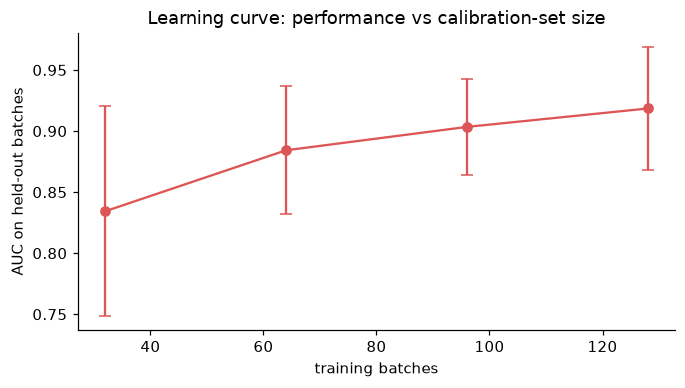

{32: np.float64(0.834), 64: np.float64(0.884), 96: np.float64(0.903), 128: np.float64(0.918)}


In [18]:
from sklearn.model_selection import StratifiedKFold
fracs = [0.25, 0.5, 0.75, 1.0]
lc = {f: [] for f in fracs}
for seed in [1, 2, 3]:
    r = np.random.default_rng(seed)
    for tr, te in StratifiedKFold(5, shuffle=True, random_state=seed).split(F, y):
        for f in fracs:
            sub = np.concatenate([r.choice(tr[y[tr] == k], max(3, int(f * (y[tr] == k).sum())), replace=False) for k in (0, 1)])
            s = sw.SensorwiseModel().fit(F.iloc[sub], y[sub]).score(F.iloc[te])
            lc[f].append(roc_auc_score(y[te], s))
mu = [np.mean(lc[f]) for f in fracs]; sd = [np.std(lc[f]) for f in fracs]
n = [int(f * len(y) * .8) for f in fracs]
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.errorbar(n, mu, yerr=sd, marker="o", color=BAD, capsize=4)
ax.set_xlabel("training batches"); ax.set_ylabel("AUC on held-out batches"); ax.set_title("Learning curve: performance vs calibration-set size")
plt.show()
print(dict(zip(n, np.round(mu, 3))))

Even with a **quarter of the data** (about 30 batches), the model is already useful, because the safe ranges and robust z-scores need only a handful of good batches. Performance keeps climbing with more data, which is exactly why **recalibration** pays off.

### 6b. Recalibration strategy

Nothing is hand-tuned, so every component re-learns from data:

| Component | How it updates |
|---|---|
| Normal levels and safe ranges | Recomputed from the accepted batches (median / max shift per sensor and mode) |
| Robust z-scores | Recomputed from accepted batches |
| ExtraTrees | Refit in seconds |
| Flag fraction | Re-tuned by CV on the enlarged set |
| Self-training | New batches the model calls *confidently accepted* (far inside all safe ranges) can join the reference set before lab labels arrive, so the normal-operation envelope grows with the process |

A new, still-acceptable source of variation (e.g. a new operating mode) gets flagged at first. Once a few such batches are confirmed good, the safe ranges widen automatically on the next refit.

## 7. Limitations and honest caveats

- 161 batches and 40 rejected, so differences below about 0.01 F1 are noise. All choices were made over 5 CV seeds for that reason.
- About 20 of the 40 rejected batches show no out-of-range level shift. The final model catches most of them through a weak combined signal, but about 5 still look normal; that's a ceiling, not a modelling failure.
- The final model's idea came from studying the missed batches, so its CV gain is probably a bit optimistic (see section 4f).
- The safe ranges assume future shifts look like calibration shifts. A larger but acceptable shift would be a false alarm. That's the brief's "unseen variability" trade-off, handled by recalibration.

## Summary

| Requirement | Our answer |
|---|---|
| Limited calibration data | Compact per-batch statistics, robust scaling, useful from about 30 batches |
| Low correlation / independent variables | Monitor each sensor separately instead of one global PCA |
| Unseen variability | 1.5× margin on safe ranges, sensor-agnostic "worst deviation" feature, refit when confirmed |
| Acceptable vs unacceptable | Learned per-sensor safe ranges for obvious faults, plus a classifier trained only on the subtle cases |
| Recalibration / self-supervised | Fully data-driven refit in seconds, confident-accepted batches extend the reference set |
| Grading metric | CV F1 0.891 → 0.931 → **0.938 (fresh seeds, final model)**, threshold tuned to F1(accepted) |